## Import Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## Product Recommendation Environment With Determinstic Reward

In [ ]:
primary_p = 0.7
np.random.choice([1,0], p = [primary_p, 1-primary_p])

0

In [ ]:
class ProductRecommendationBandit:
  def __init__(self,num_products, recomendation_probabilities, product_rewards):
    if len(recomendation_probabilities) != len(product_rewards):
      raise ValueError('Size of recommendation probabilities does not match the size of product rewards')

    self.num_products = num_products
    self.recomendation_probabilities = recomendation_probabilities
    self.product_rewards = product_rewards

  def get_recommendation(self,product):
    if not (0 <= product <= self.num_products):
      raise ValueError(f'Product index must be between 0 and {self.num_ptoducts - 1}')

    return np.random.choice([self.product_rewards[product],0.0],
                            p = [self.recomendation_probabilities[product], 1- self.recomendation_probabilities[product]])



In [ ]:
recom_probabilities = [0.52, 0.08, 0.87, 0.56]

env = ProductRecommendationBandit(num_products= 4, recomendation_probabilities= recom_probabilities, product_rewards= [1.0, 1.0, 1.0, 1.0])


In [ ]:
[env.get_recommendation(1) for _ in range(10)]

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [ ]:
[env.get_recommendation(2) for _ in range(10)]

[1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0]

In [ ]:
class PolicyAgents:

  def __init__(self, environment, agent_type, epsilon = 0.01, tau = 1, n_th_iteration = None, C=2):
    self.environment = environment
    self.agent_type = agent_type
    self.q_values = np.zeros(self.environment.num_products)
    self.rewards = []
    self.selected_arm_list = []
    self.cum_rewards = [0.0]
    self.total_reward = 0
    self.arm_counts = np.zeros(self.environment.num_products)

    # just for epsilon greedy agent
    self.epsilon = epsilon


    # just for softmax function
    self.action_probs = np.zeros(self.environment.num_products)
    self.tau = tau


    # just for UBC algorithm
    self.n_th_iteration = n_th_iteration
    self.C = C

    # just for regret part only
    self.regret = []
    self.greedy_reward_list = []
    self.total_reward_list = []
    self.best_total_reward = 0
    self.total_regret = 0
    self.total_reward_episode = 0

  def choose_action(self):
    if self.agent_type == 'random':
      selected_arm = np.random.randint(self.environment.num_products)
    elif self.agent_type == 'greedy':
      selected_arm  = np.argmax(self.q_values)
    elif self.agent_type == 'egreedy':
      if np.random.random() < self.epsilon:
        selected_arm = np.random.randint(self.environment.num_products)
      else:
        selected_arm  = np.argmax(self.q_values)
    elif self.agent_type == 'softmax':
      self.action_probs = np.exp(self.q_values / self.tau) / np.sum(np.exp(self.q_values / self.tau))
      selected_arm = np.random.choice(self.environment.num_products, p= self.action_probs)
    elif self.agent_type == 'ubc':
      if self.n_th_iteration < len(self.q_values):
        selected_arm = self.n_th_iteration
      else:
        U = self.C * np.sqrt(np.log(self.n_th_iteration) / self.arm_counts)
        selected_arm = np.argmax(self.q_values + U)

    return selected_arm

  def take_action(self):
    chosen_product = self.choose_action()
    self.selected_arm_list.append(chosen_product)
    reward = self.environment.get_recommendation(chosen_product)

    self.rewards.append(reward)
    self.arm_counts[chosen_product] = self.arm_counts[chosen_product] + 1
    self.total_reward += reward

    # update Q-values for the chosen product
    self.q_values[chosen_product] = self.q_values[chosen_product] + (1/self.arm_counts[chosen_product]) * (reward - self.q_values[chosen_product])

    self.cum_rewards.append(sum(self.rewards)/ len(self.rewards))

    # for regret part only
    self.total_reward_episode = reward + self.total_reward_episode
    self.total_reward_list.append(self.total_reward_episode)
    best_possible_product = np.argmax(self.q_values)
    best_possible_reward = self.environment.get_recommendation(best_possible_product)
    self.best_total_reward = self.best_total_reward + best_possible_reward
    self.greedy_reward_list.append(self.best_total_reward)
    regret = abs(best_possible_reward - reward)
    self.total_regret = self.total_regret + regret
    self.regret.append(self.total_regret)

    return chosen_product, reward

  def get_total_reward(self):
    return self.total_reward

  def get_q_values(self):
    return self.q_values

  def get_reward_distribution(self):
    reward_dict = {}

    for arm, reward in zip(self.selected_arm_list, self.rewards):
      if arm not in reward_dict:
        reward_dict[arm] = []

      reward_dict[arm].append(reward)
    return reward_dict

  # only regret part
  def get_regret(self):
    return self.regret

  # only regret part
  def get_reward_list(self):
    return self.total_reward_list

  # only regret part
  def get_greedy_reward_list(self):
    return self.greedy_reward_list



In [ ]:
# Create an Instance of Random Agent

random_agent = PolicyAgents(environment= env, agent_type= 'random')

In [ ]:
# Play the random agent for 1000 times

num_steps = 1000
for _ in range(num_steps):
  chosen_product, reward  = random_agent.take_action()


In [ ]:
random_toal_reward = random_agent.get_total_reward()
random_q_values = random_agent.get_q_values()

In [ ]:
# Print the results
print(f'Total Reward: {random_toal_reward}')
print(f'Q Values: {random_q_values}')

Total Reward: 500.0
Q Values: [0.546875   0.05976096 0.89166667 0.51778656]


In [ ]:
print(f'Q-values: {random_q_values}')
print(f'Actual Probabilities {recom_probabilities}')

Q-values: [0.546875   0.05976096 0.89166667 0.51778656]
Actual Probabilities [0.52, 0.08, 0.87, 0.56]


### Plot Function

In [ ]:
def plot_cumulative_rewards_and_counts(cum_rewards, arm_counts, reward_dict):
  # create a baseline chart
  baseline = [1.0] * len(cum_rewards)

  plt.figure(figsize= (18, 6))

  #first plot: cumulative rewards
  plt.subplot(1,3,1)
  plt.plot(cum_rewards, label = 'Cumulative Rewards')
  plt.plot(baseline, linestyle = '--', label = 'Baseline (1.0)', color = 'red')
  plt.title('Cumulative Rewards over time')
  plt.xlabel('Steps')
  plt.ylabel('Cumulative Rewards')
  plt.legend()


  # second plot: pie chart that shows number of times each arm is selected
  plt.subplot(1,3,2)
  plt.pie(arm_counts, labels = range(len(arm_counts)), autopct= '%1.1f%%', startangle= 140)
  plt.title('Number of time each product is selected')
  plt.axis('equal')

  # thrid chart:  Violin chart for reward dist
  plt.subplot(1,3,3)

  reward_data = [reward_dict[key] for key in sorted(reward_dict.keys())]
  plt.violinplot(reward_data, showmedians= True, showextrema= False)
  plt.xticks(range(1, len(reward_dict)+1), sorted(reward_dict.keys()))
  plt.title('Reward distribution for each product')
  plt.xlabel('Product')
  plt.ylabel('Reward')

  plt.tight_layout()
  plt.show()





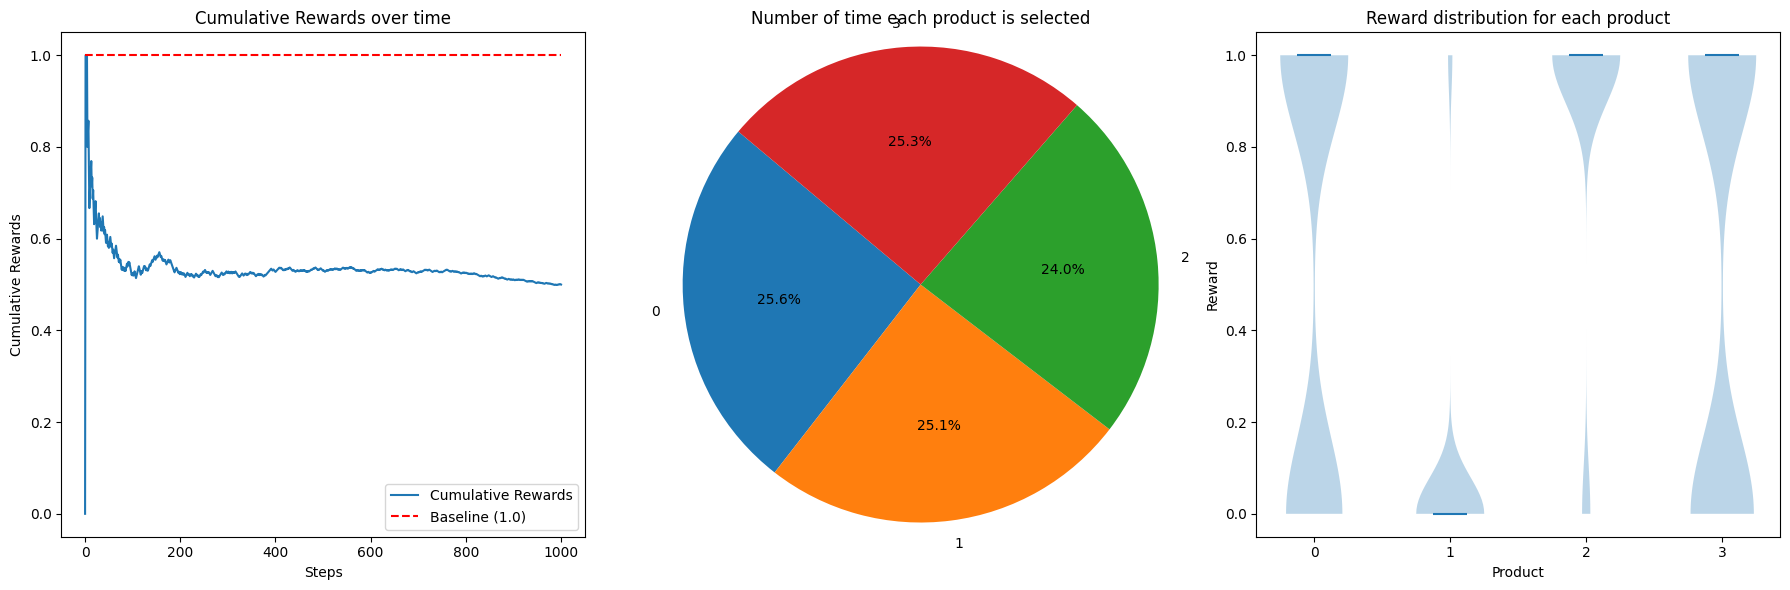

In [ ]:
random_cum_rewards = random_agent.cum_rewards
random_arm_counts = random_agent.arm_counts
random_reward_distribution = random_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(random_cum_rewards, random_arm_counts, random_reward_distribution)

### Greedy Agent

In [ ]:
greedy_agent = PolicyAgents(env, agent_type = 'greedy')

num_steps = 1000
for _ in range(num_steps):
  chosen_product, reward = greedy_agent.take_action()


In [ ]:
greedy_toal_reward = greedy_agent.get_total_reward()
greedy_q_values = greedy_agent.get_q_values()

In [ ]:
# Print the results
print(f'Total Reward: {greedy_toal_reward}')
print(f'Q Values: {greedy_q_values}')

Total Reward: 537.0
Q Values: [0.537 0.    0.    0.   ]


In [ ]:
print(f'Q-values: {greedy_q_values}')
print(f'Actual Probabilities {recom_probabilities}')

Q-values: [0.537 0.    0.    0.   ]
Actual Probabilities [0.52, 0.08, 0.87, 0.56]


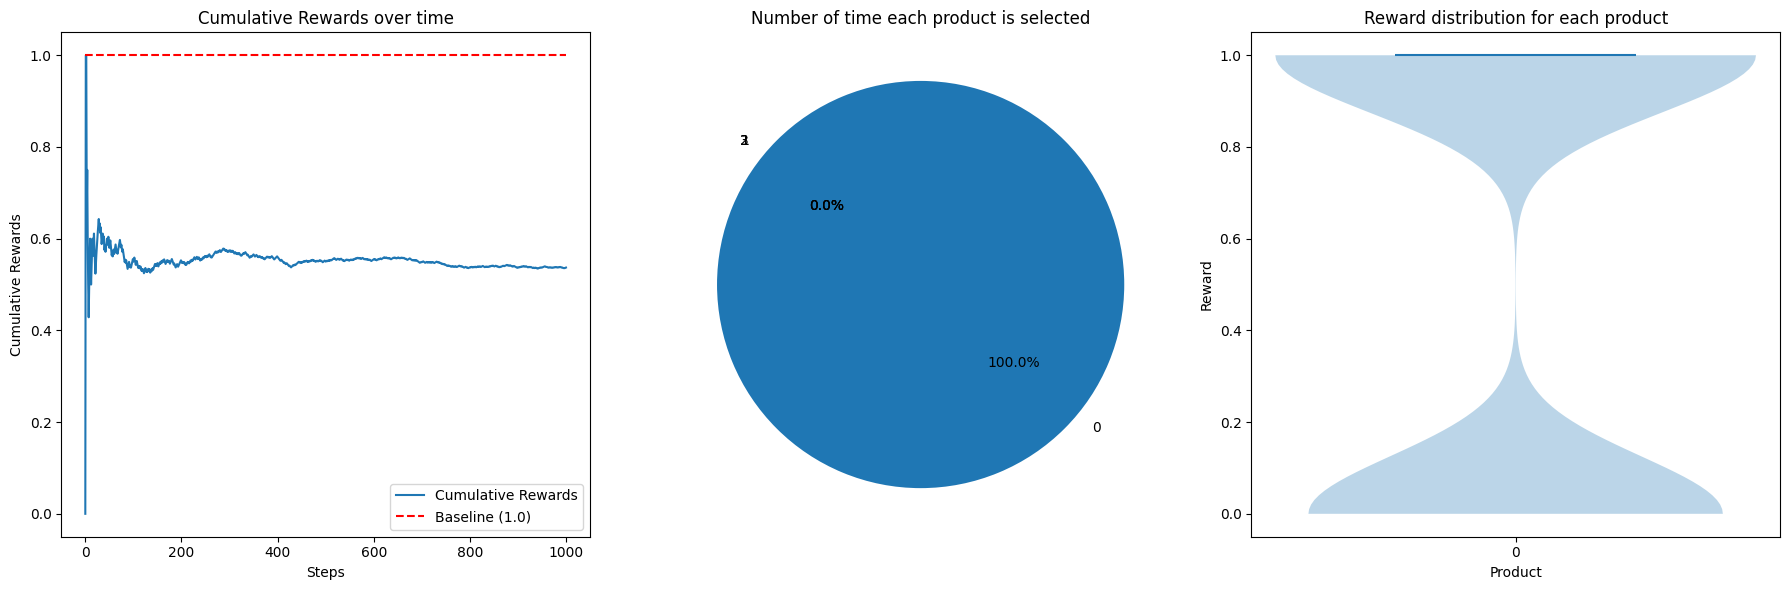

In [ ]:
greedy_cum_rewards = greedy_agent.cum_rewards
greedy_arm_counts = greedy_agent.arm_counts
greedy_reward_distribution = greedy_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(greedy_cum_rewards, greedy_arm_counts, greedy_reward_distribution)

### E-greedy Agent

In [ ]:
egreedy_agent = PolicyAgents(env, agent_type = 'egreedy')

num_steps = 1000
for _ in range(num_steps):
  chosen_product, reward = egreedy_agent.take_action()

In [ ]:
egreedy_toal_reward = egreedy_agent.get_total_reward()
egreedy_q_values = egreedy_agent.get_q_values()

In [ ]:
# Print the results
print(f'Total Reward: {egreedy_toal_reward}')
print(f'Q Values: {egreedy_q_values}')

Total Reward: 711.0
Q Values: [0.5        0.         0.86101695 0.6       ]


In [ ]:
print(f'Q-values: {egreedy_q_values}')
print(f'Actual Probabilities {recom_probabilities}')

Q-values: [0.5        0.         0.86101695 0.6       ]
Actual Probabilities [0.52, 0.08, 0.87, 0.56]


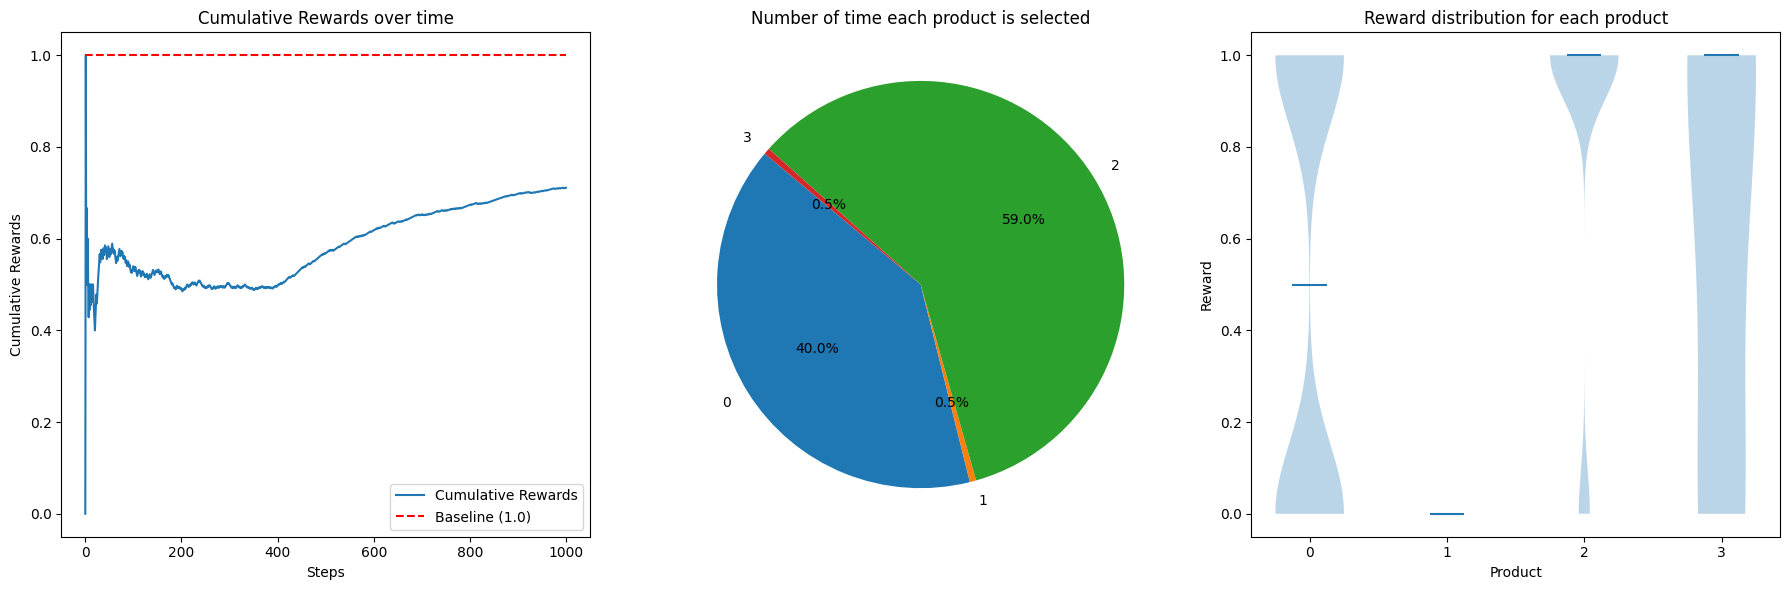

In [ ]:
egreedy_cum_rewards = egreedy_agent.cum_rewards
egreedy_arm_counts = egreedy_agent.arm_counts
egreedy_reward_distribution = egreedy_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(egreedy_cum_rewards, egreedy_arm_counts, egreedy_reward_distribution)

### Epsilon Parameter Tuning

In [ ]:
# List of potential epsilon parameter
epsilon_values = [0.01, 0.05, 0.1, 0.2, 0.3]

# function for running egreedy algorithm for each parameter

def run_agent_with_epsilon(selected_epsilon):
  egreedy_agent = PolicyAgents(env, agent_type = 'egreedy', epsilon= selected_epsilon)

  total_rewards = []

  num_steps = 1000
  for _ in range(num_steps):
    chosen_product, reward = egreedy_agent.take_action()

  egreedy_total_reward = egreedy_agent.get_total_reward()
  total_rewards.append(egreedy_total_reward)

  return total_rewards




In [ ]:
results_dict = {}

# run the agent for each epsilon

for epsilon_value in epsilon_values:
  total_rewards = run_agent_with_epsilon(selected_epsilon = epsilon_value)
  results_dict[f'Epsilon={epsilon_value}'] = total_rewards


In [ ]:
def plot_results(results_dict):
  labels = list(results_dict.keys())
  total_rewards = list(results_dict.values())


  x = np.arange(len(labels))

  width = 0.35

  fig, ax = plt.subplots()

  # convert total reward list into array
  total_rewards = np.array(total_rewards)

  # plot
  for i in range(len(labels)):
    ax.bar(x[i], total_rewards[i], width, label = f'{labels[i]}')

  ax.set_ylabel('Total Reward')
  ax.set_title('Total Reward by Epsilon Value')
  ax.set_xticks(x)
  ax.set_xticklabels(labels)

  plt.show()

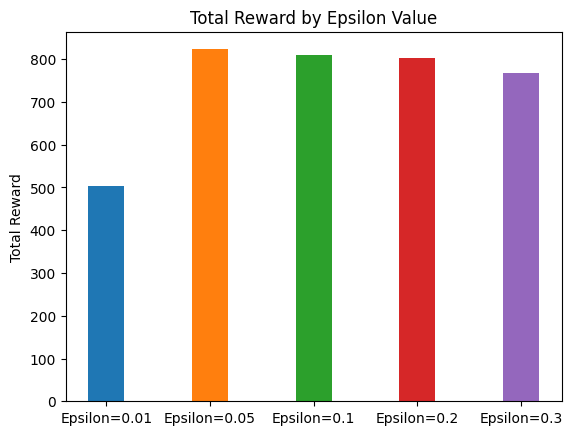

In [ ]:
plot_results(results_dict)

## Product Recommendation Env with Stochastic and Nonstationary Reward

In [ ]:
class stochasticProductRecommendationBandit:
  def __init__(self, num_products, seed = 48):
    self.num_products = num_products
    self.seed  = seed

    # random seed
    np.random.seed(self.seed)

    # generate radom recommendation probabilities from normal distribution
    self.recommendation_probabilities = np.clip(np.random.normal(loc=0.5, scale = 0.2, size = self.num_products),0,1)

    # generate random product rewards
    self.product_rewards = np.clip(np.random.normal(loc = 0.5, scale= 0.2, size= self.num_products), 0,1)


  def get_recommendation(self, product):
    if not (0 <= product < self.num_products):
      raise ValueError(f'Product index must be between 0 and {self.num_products - 1}')

    return np.random.choice([self.product_rewards[product], 0.0],
                            p = [self.recommendation_probabilities[product], 1- self.recommendation_probabilities[product]])


In [ ]:
# create an instance of stochastic env

num_products = 4

env = stochasticProductRecommendationBandit(num_products= num_products)

# Access to the recommendation probs and product rewards

print("Recommendation Probabilities:", env.recommendation_probabilities)
print("Product Rewards:", env.product_rewards)

Recommendation Probabilities: [0.30127374 0.28731984 0.37238482 0.71231774]
Product Rewards: [0.46851917 0.7187457  0.0850292  0.6401266 ]


### Random Agent: Stochastic Reward

In [ ]:
# Create an instance of RandomPolicyAgent
random_agent = PolicyAgents(env, agent_type = 'random')

# Interact with the environment using the agent for a certain number of steps (for example, 100 steps)
num_steps = 1000
for _ in range(num_steps):
    chosen_product, reward = random_agent.take_action()

# Get the total reward obtained by the agent and Q-values
random_total_reward = random_agent.get_total_reward()
random_q_values = random_agent.get_q_values()


# Print the results
print(f"Total Reward: {random_total_reward}")
print(f"Q-values: {random_q_values}")

Total Reward: 215.23081933661197
Q-values: [0.12480205 0.20738512 0.03408343 0.44877203]


In [ ]:
print(f"Q-values: {random_q_values}")
print(f"Actual_Probs: {recom_probabilities}")

Q-values: [0.12480205 0.20738512 0.03408343 0.44877203]
Actual_Probs: [0.52, 0.08, 0.87, 0.56]


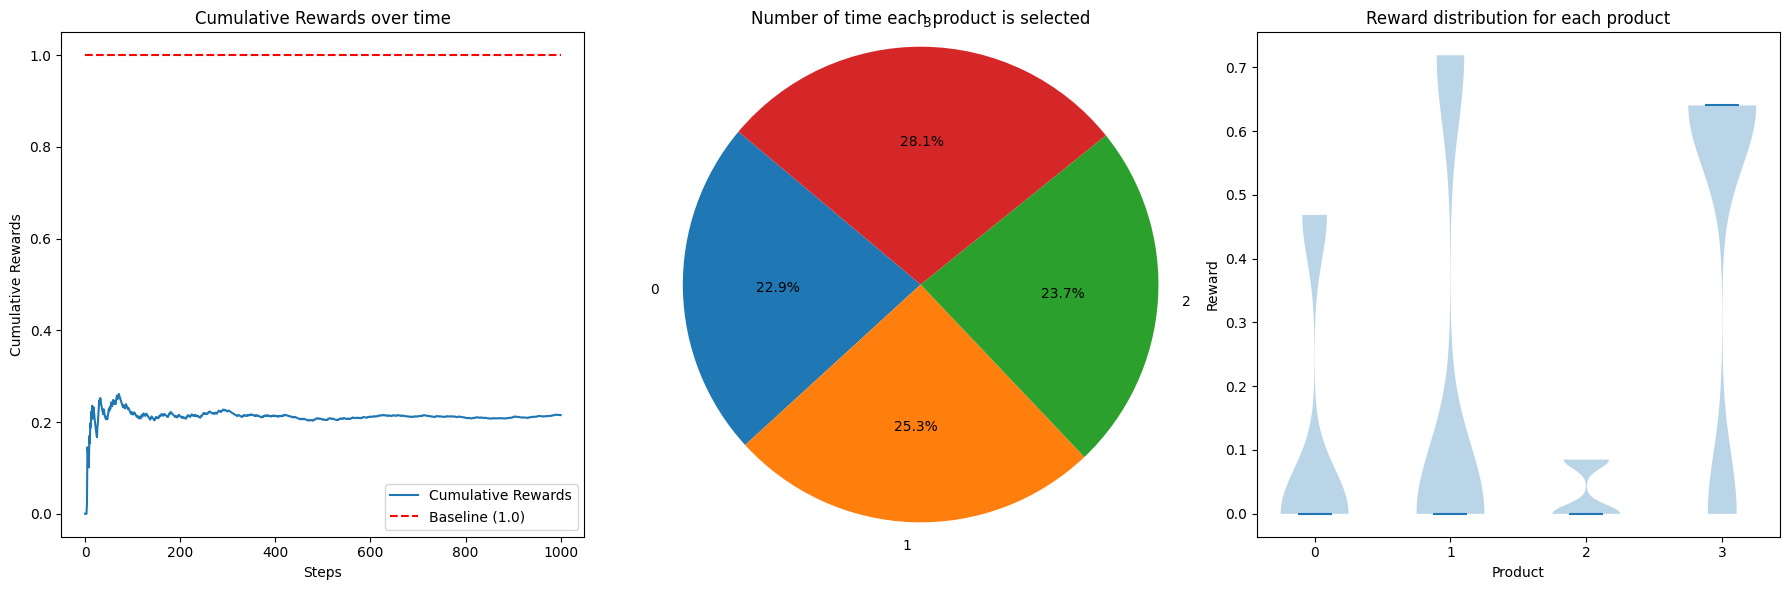

In [ ]:

random_cum_rewards = random_agent.cum_rewards
random_arm_counts = random_agent.arm_counts
random_reward_distribution = random_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(random_cum_rewards, random_arm_counts, random_reward_distribution)

## Greedy Agent: Stochastic Reward

In [ ]:
# Create an instance of Greedt Policy Agent
greedy_agent = PolicyAgents(env, agent_type = 'greedy')

# Interact with the environment using the agent for a certain number of steps (for example, 100 steps)
num_steps = 1000
for _ in range(num_steps):
    chosen_product, reward = greedy_agent.take_action()

# Get the total reward obtained by the agent and Q-values
greedy_total_reward = greedy_agent.get_total_reward()
greedy_q_values = greedy_agent.get_q_values()

# Print the results
print(f"Total Reward: {greedy_total_reward}")
print(f"Q-values: {greedy_q_values}")

Total Reward: 148.52057680208978
Q-values: [0.14852058 0.         0.         0.        ]


In [ ]:
print(f"Q-values: {greedy_q_values}")
print(f"Actual_Probs: {recom_probabilities}")

Q-values: [0.14852058 0.         0.         0.        ]
Actual_Probs: [0.52, 0.08, 0.87, 0.56]


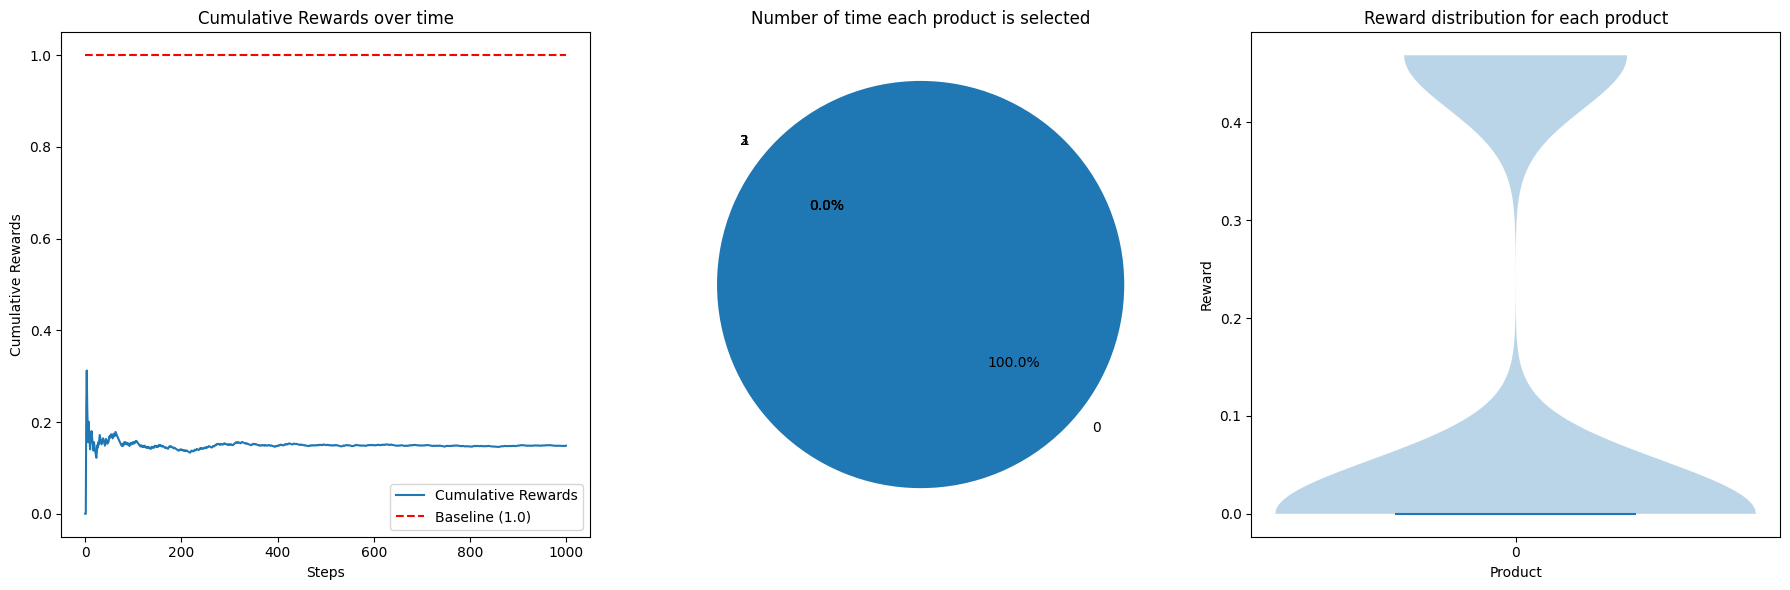

In [ ]:
# Assuming greedy_agent.cum_rewards contains the cumulative rewards
greedy_cum_rewards = greedy_agent.cum_rewards
greedy_arm_counts = greedy_agent.arm_counts
greedy_reward_distribution = greedy_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(greedy_cum_rewards, greedy_arm_counts, greedy_reward_distribution)

## Egreedy Agent: Stochastic Env

In [ ]:
# Create an instance of RandomPolicyAgent
egreedy_agent = PolicyAgents(env, agent_type = 'egreedy', epsilon = 0.01)

# Interact with the environment using the agent for a certain number of steps (for example, 100 steps)
num_steps = 1000
for _ in range(num_steps):
    chosen_product, reward = egreedy_agent.take_action()

# Get the total reward obtained by the agent and Q-values
egreedy_total_reward = egreedy_agent.get_total_reward()
egreedy_q_values = egreedy_agent.get_q_values()

# Print the results
print(f"Total Reward: {egreedy_total_reward}")
print(f"Q-values: {egreedy_q_values}")

Total Reward: 179.28670473673938
Q-values: [0.13830429 0.2395819  0.         0.47476056]


In [ ]:
print(f"Q-values: {egreedy_q_values}")
print(f"Actual_Probs: {recom_probabilities}")

Q-values: [0.13830429 0.2395819  0.         0.47476056]
Actual_Probs: [0.52, 0.08, 0.87, 0.56]


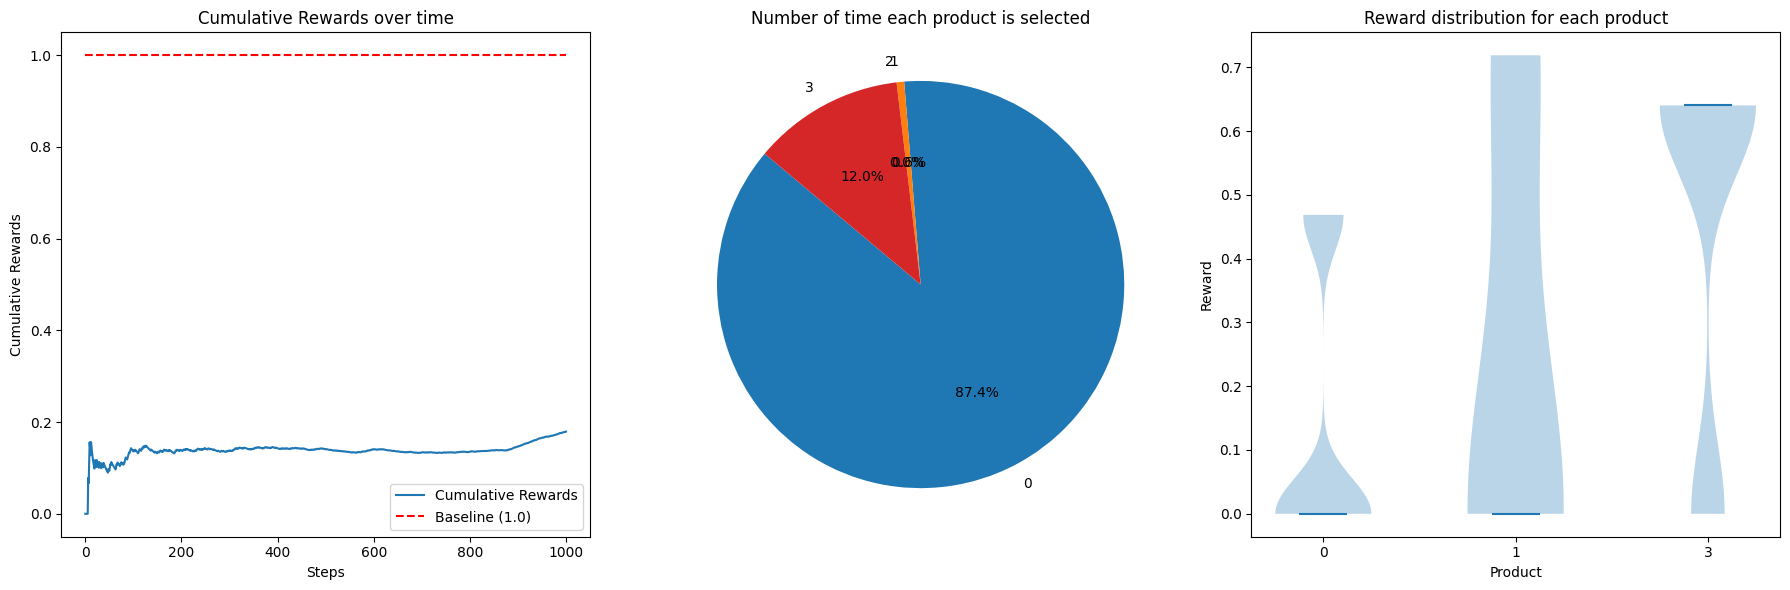

In [ ]:
# Assuming Egreedy_agent.cum_rewards contains the cumulative rewards
egreedy_cum_rewards = egreedy_agent.cum_rewards
egreedy_arm_counts = egreedy_agent.arm_counts
egreedy_reward_distribution = egreedy_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(egreedy_cum_rewards, egreedy_arm_counts, egreedy_reward_distribution)

## Softmax Function: Stochastic Env

In [ ]:
# Create an instance of Greedt Policy Agent
softmax_agent = PolicyAgents(env, agent_type = 'softmax', tau = 0.5)

# Interact with the environment using the agent for a certain number of steps (for example, 100 steps)
num_steps = 1000
for _ in range(num_steps):
    chosen_product, reward = softmax_agent.take_action()

# Get the total reward obtained by the agent and Q-values
softmax_total_reward = softmax_agent.get_total_reward()
softmax_q_values = softmax_agent.get_q_values()

# Print the results
print(f"Total Reward: {softmax_total_reward}")
print(f"Q-values: {softmax_q_values}")

Total Reward: 274.24510073095445
Q-values: [0.11274525 0.22883832 0.03360435 0.46458361]


In [ ]:
print(f"Q-values: {softmax_q_values}")
print(f"Actual_Probs: {recom_probabilities}")

Q-values: [0.11274525 0.22883832 0.03360435 0.46458361]
Actual_Probs: [0.52, 0.08, 0.87, 0.56]


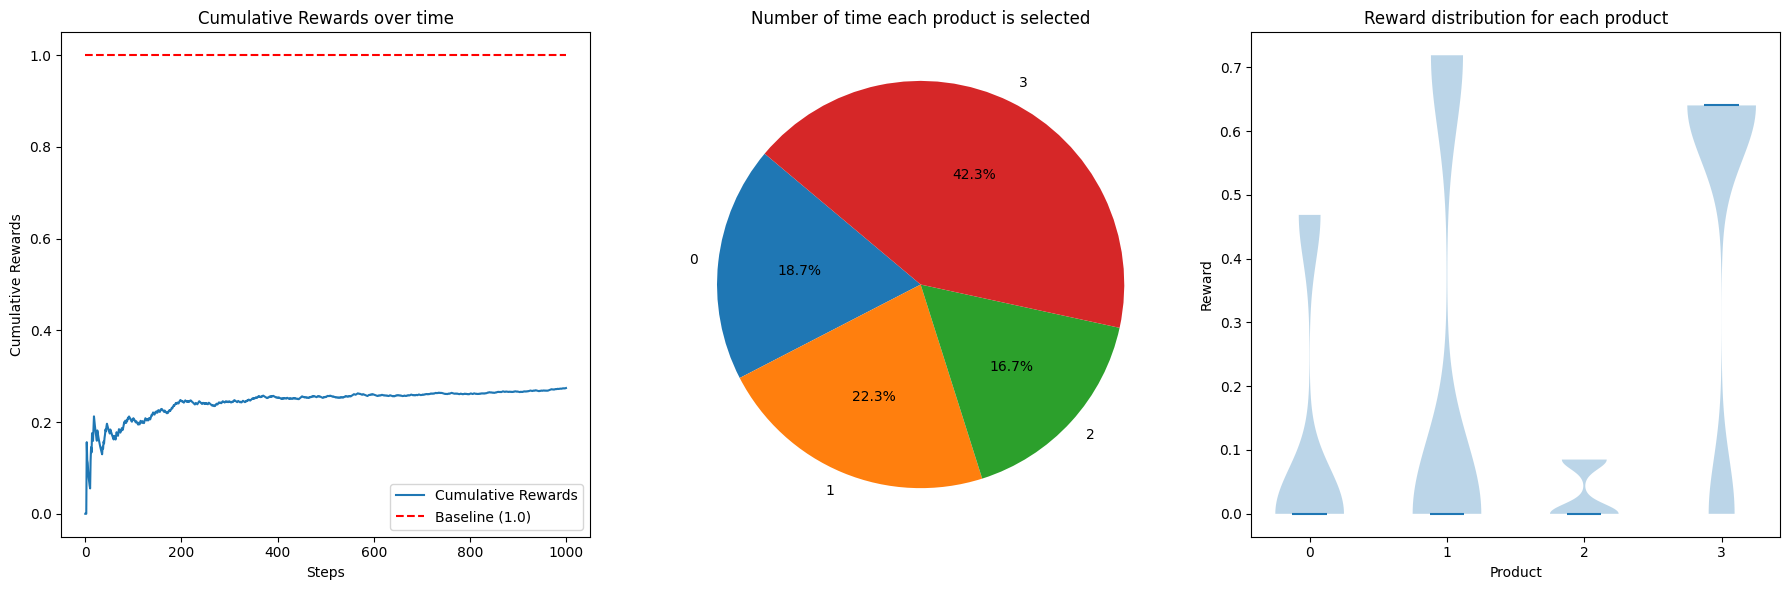

In [ ]:
# Assuming softmax_agent.cum_rewards contains the cumulative rewards
softmax_cum_rewards = softmax_agent.cum_rewards
softmax_arm_counts = softmax_agent.arm_counts
softmax_reward_distribution = softmax_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(softmax_cum_rewards, softmax_arm_counts, softmax_reward_distribution)

## Upper Confidence Bounds (UCB) Agent: Stochastic Env

In [ ]:
# Create an instance of Greedt Policy Agent
ubc_agent = PolicyAgents(env, agent_type = 'ubc', C = 1)

# Interact with the environment using the agent for a certain number of steps (for example, 100 steps)
num_steps = 1000
for i in range(num_steps):
  ubc_agent.n_th_iteration = i
  chosen_product, reward = ubc_agent.take_action()

# Get the total reward obtained by the agent and Q-values
ubc_total_reward = ubc_agent.get_total_reward()
ubc_q_values = ubc_agent.get_q_values()

# Print the results
print(f"Total Reward: {ubc_total_reward}")
print(f"Q-values: {ubc_q_values}")

Total Reward: 418.48338145829825
Q-values: [0.14907428 0.27152615 0.03270354 0.46028151]


In [ ]:
print(f"Q-values: {ubc_q_values}")
print(f"Actual_Probs: {recom_probabilities}")

Q-values: [0.14907428 0.27152615 0.03270354 0.46028151]
Actual_Probs: [0.52, 0.08, 0.87, 0.56]


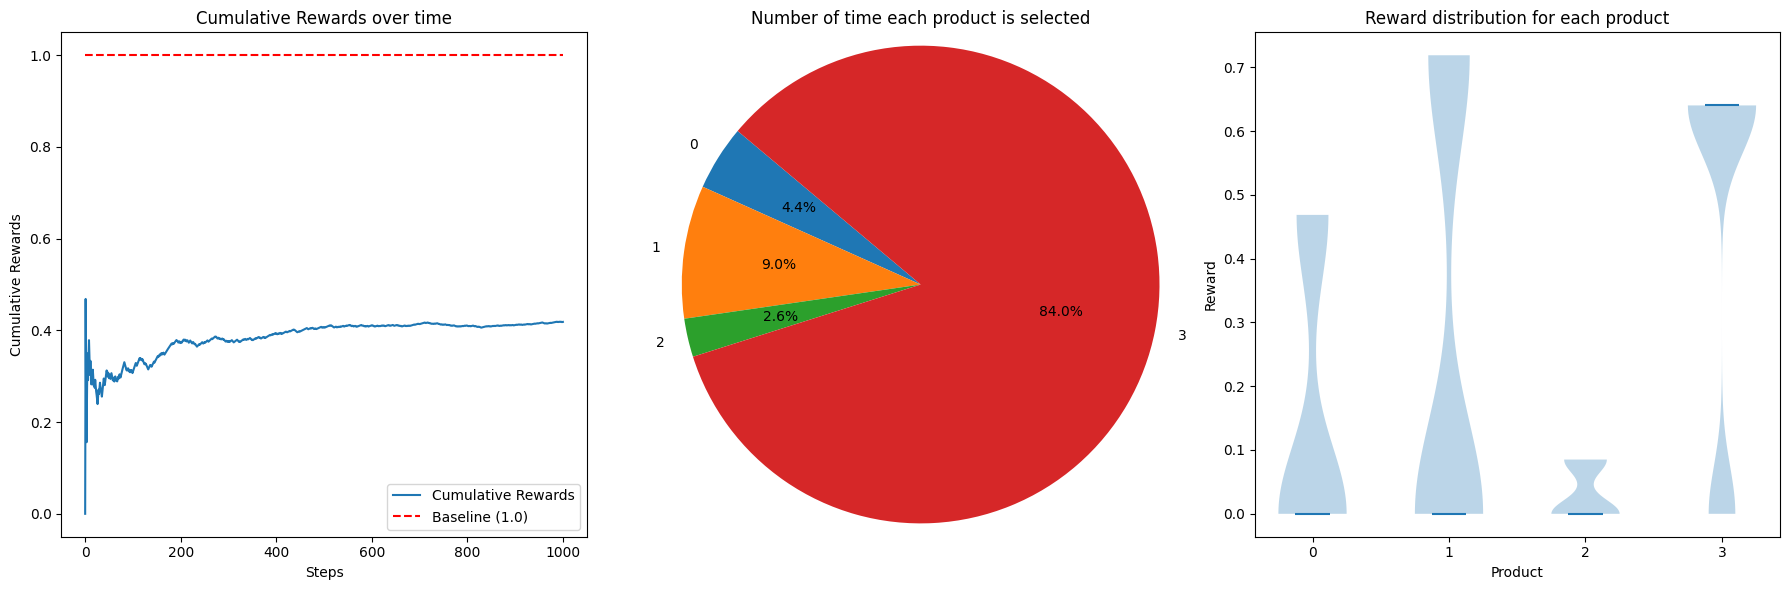

In [ ]:
# Assuming ubc_agent.cum_rewards contains the cumulative rewards
ubc_cum_rewards = ubc_agent.cum_rewards
ubc_arm_counts = ubc_agent.arm_counts
ubc_reward_distribution = ubc_agent.get_reward_distribution()

plot_cumulative_rewards_and_counts(ubc_cum_rewards, ubc_arm_counts, ubc_reward_distribution)

## Compare accumulated rewards for all the agents in one chart

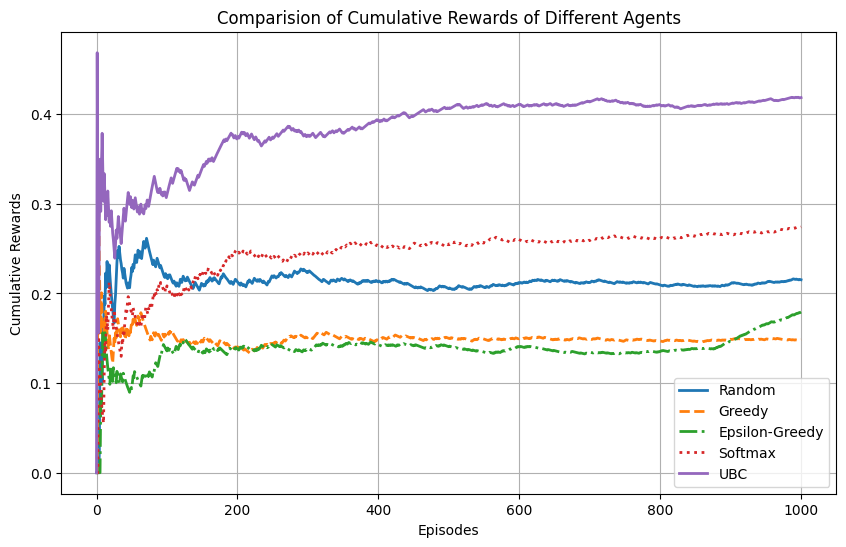

In [ ]:
ln_width = 2
x_values = list(range(len(random_cum_rewards)))

plt.figure(figsize= (10, 6))

plt.plot(x_values, random_cum_rewards, label = 'Random', linestyle = '-', linewidth = ln_width)
plt.plot(x_values, greedy_cum_rewards, label = 'Greedy', linestyle = '--', linewidth = ln_width)
plt.plot(x_values, egreedy_cum_rewards, label = 'Epsilon-Greedy', linestyle = '-.', linewidth = ln_width)
plt.plot(x_values, softmax_cum_rewards, label = 'Softmax', linestyle = ':', linewidth = ln_width)
plt.plot(x_values, ubc_cum_rewards, label = 'UBC', linestyle = '-', linewidth = ln_width)

plt.xlabel('Episodes')
plt.ylabel('Cumulative Rewards')
plt.title('Comparision of Cumulative Rewards of Different Agents')
plt.legend()
plt.grid(True)
plt.show()

## Regret Concept

In [ ]:
# Visualization

def regret_curve(x_values, y_lists, labels, title, xlabel, ylabel):
  fig, axes = plt.subplots(1,2, figsize = (15,6))

  # first plot
  for y_list, label in zip(y_lists, labels):
    axes[0].plot(x_values, y_list, label = label)


  axes[0].set_title(title)
  axes[0].set_xlabel(xlabel)
  axes[0].set_ylabel(ylabel)
  axes[0].legend()
  axes[0].grid(True)


  # plot regret
  regret_label = labels[1]
  axes[1].plot(x_values, y_lists[1], label = regret_label)
  axes[1].set_title(f'{title}')
  axes[1].set_xlabel(xlabel)
  axes[1].set_ylabel(ylabel)
  axes[1].legend()
  axes[1].grid(True)

  plt.show()

## Determinsitic Regret

In [ ]:
recom_probabilities = [0.52, 0.08, 0.87, 0.56]

reward_list_det = [1.0, 1.0, 1.0, 1.0]

env_det = ProductRecommendationBandit(num_products= 4, recomendation_probabilities= recom_probabilities, product_rewards= reward_list_det)


In [ ]:
# Create an instance of egreedy agent for determinstic env

egreedy_agent = PolicyAgents(env_det, agent_type= 'egreedy', epsilon= 0.01)

num_steps = 1000
for _ in range(num_steps):
  chosen_product, reward = egreedy_agent.take_action()

# obtain  resuls
reward_list = egreedy_agent.get_reward_list()
regret_list = egreedy_agent.get_regret()
greedy_reward_list = egreedy_agent.get_greedy_reward_list()

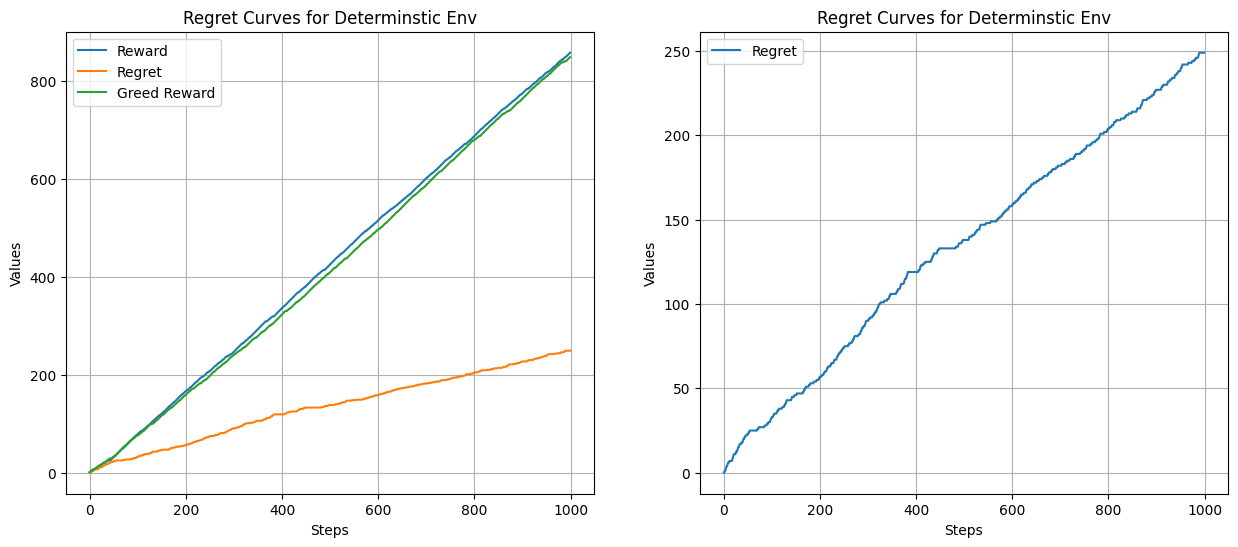

In [ ]:
steps = range(len(reward_list))
y_lists = [reward_list, regret_list, greedy_reward_list]
labels = ['Reward', 'Regret', 'Greed Reward']

regret_curve(steps, y_lists, labels, 'Regret Curves for Determinstic Env', 'Steps', 'Values')

## Regret Curves for Stochstic Environment

In [ ]:
# create a stochastic env
num_products = 4
env = stochasticProductRecommendationBandit(num_products)

In [ ]:
 # Create an instance of RandomPolicyAgent
egreedy_agent = PolicyAgents(env, agent_type = 'egreedy', epsilon = 0.01)

# Interact with the environment using the agent for a certain number of steps (for example, 100 steps)
num_steps = 1000
for _ in range(num_steps):
    chosen_product, reward = egreedy_agent.take_action()

# get reward list, regret list, greedy_reward_list
reward_list = egreedy_agent.get_reward_list()
regret_list = egreedy_agent.get_regret()
greed_reward_list = egreedy_agent.get_greedy_reward_list()


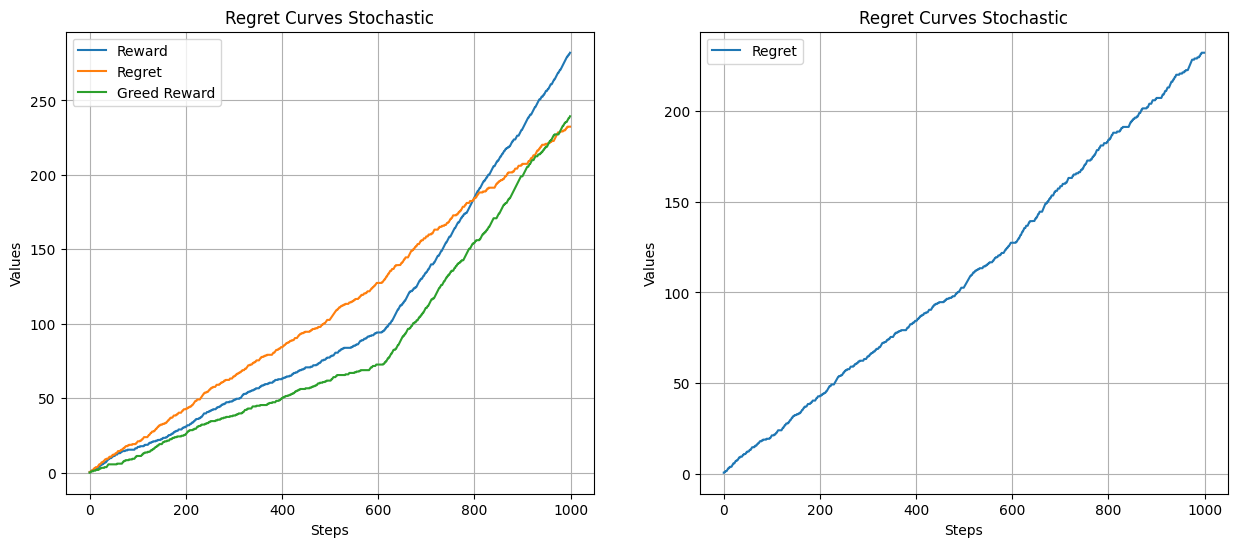

In [ ]:


steps = range(len(reward_list))
y_lists = [reward_list, regret_list, greed_reward_list]
labels = ['Reward', 'Regret', 'Greed Reward']

regret_curve(steps, y_lists, labels, 'Regret Curves Stochastic', 'Steps', 'Values')
